# Open Set Model Selection

This notebook compares unknown rejection choices without opening Session 3. It separates three decisions: the confidence rule, the exact fine tuning checkpoint, and the effect of that checkpoint.

© 2026 Emma Tong. All rights reserved.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
print("Session 3 accessed: False")

Session 3 accessed: False


## 1. What is being selected

A closed set classifier must choose one of the seven catalog dolls. An open set system gets one more option: reject the photo as unknown. The rejection decision needs a confidence score and a threshold.

## 2. The validation data

Session 1 provides 98 known reference photos. Session 2 provides 42 known validation photos. Session 4 provides 51 unknown validation photos from four physical products. Session 3 is not loaded or inspected.

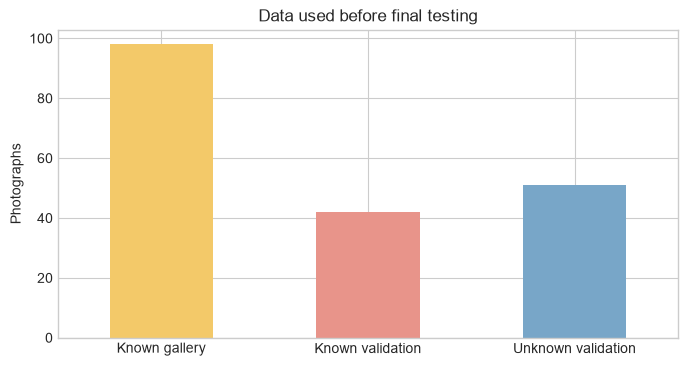

In [2]:
counts = pd.Series(
    {"Known gallery": 98, "Known validation": 42, "Unknown validation": 51}
)
ax = counts.plot.bar(color=["#f3c969", "#e8948a", "#78a6c8"], figsize=(8, 4))
ax.set_ylabel("Photographs")
ax.set_title("Data used before final testing")
plt.xticks(rotation=0)
plt.show()

## 3. The retention constraint

A threshold is eligible only if at least 95 percent of known validation photos are both classified correctly and accepted. With 42 known photos, that means at least 40 must survive. This prevents a trivial solution that rejects everything.

## 4. Four embedding confidence signals

Maximum similarity uses the closest reference photo. Identity margin measures the gap between the first and second identity. Five neighbor agreement asks what fraction of the five closest reference photos vote for the predicted identity. Prototype similarity compares the query with one mean vector per identity.

In [3]:
frozen = pd.DataFrame(
    [
        ("Maximum similarity", 40, 7, 0.820814),
        ("Identity margin", 40, 13, 0.021654),
        ("Five neighbor agreement", 40, 22, 0.600000),
        ("Prototype similarity", 40, 11, 0.799924),
    ],
    columns=["Confidence", "Correct known accepted", "Unknown accepted", "Threshold"],
)
frozen

,Confidence,Correct known accepted,Unknown accepted,Threshold
0,Maximum similarity,40,7,0.820814
1,Identity margin,40,13,0.021654
2,Five neighbor agreement,40,22,0.600000
3,Prototype similarity,40,11,0.799924


## 5. Reading the frozen comparison

Lower unknown accepted is better, as long as correct known accepted stays at 40 or more. Maximum similarity wins here with 7 false accepts. Margin, neighbor agreement, and prototypes add complexity but do not improve this frozen model.

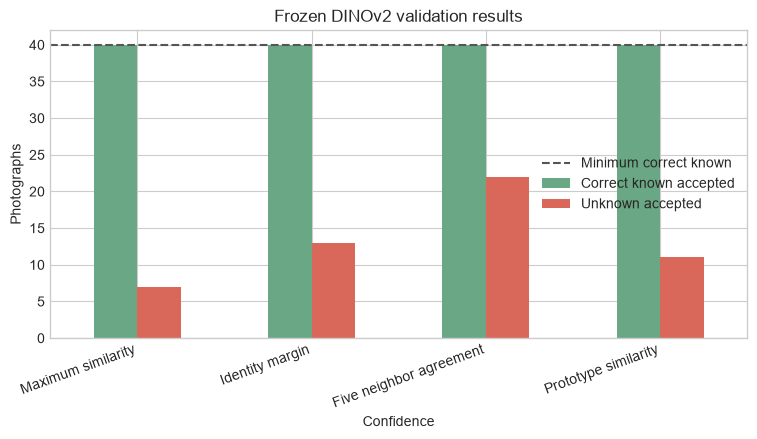

In [4]:
ax = frozen.set_index("Confidence")[
    ["Correct known accepted", "Unknown accepted"]
].plot.bar(figsize=(9, 4), color=["#6aa784", "#d9685a"])
ax.axhline(40, color="#555555", linestyle="--", label="Minimum correct known")
ax.set_ylabel("Photographs")
ax.set_title("Frozen DINOv2 validation results")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.show()

## 6. Frozen rule

Maximum similarity is the frozen baseline confidence rule. The chosen threshold is 0.820814. Forty known photos are correctly accepted and 7 unknown photos are falsely accepted. Every accepted known prediction is correct.

## 7. Checkpoint selection comes first

The fine tuning checkpoint is selected using only known Session 2 validation loss. Unknown photos are not consulted. Among the three conservative augmentation runs, seed 42 has the lowest loss.

In [5]:
checkpoint = pd.Series(
    {
        "Run ID": "c62a6ff28d2e",
        "Seed": 42,
        "Selected epoch": 22,
        "Known validation loss": 0.0023071798495948315,
        "Session 3 accessed": False,
    }
)
checkpoint.to_frame("Selected checkpoint")

,Selected checkpoint
Run ID,c62a6ff28d2e
Seed,42
Selected epoch,22
Known validation loss,0.002307
Session 3 accessed,False


## 8. Why this order matters

If I chose the checkpoint after looking at unknown rejection, I would be using the same unknown photos for model selection and evaluation. Freezing the checkpoint first makes the later comparison more honest.

## 9. Apples to apples model comparison

The cleanest measurement keeps the confidence definition fixed. Both models use maximum similarity. Only the image representation changes from frozen DINOv2 to the selected tuned backbone.

In [6]:
same_rule = pd.DataFrame(
    [
        ("Frozen DINOv2", 40, 7, 0.820814),
        ("Partially tuned DINOv2", 41, 4, 0.611551),
    ],
    columns=["Model", "Correct known accepted", "Unknown accepted", "Threshold"],
)
same_rule

,Model,Correct known accepted,Unknown accepted,Threshold
0,Frozen DINOv2,40,7,0.820814
1,Partially tuned DINOv2,41,4,0.611551


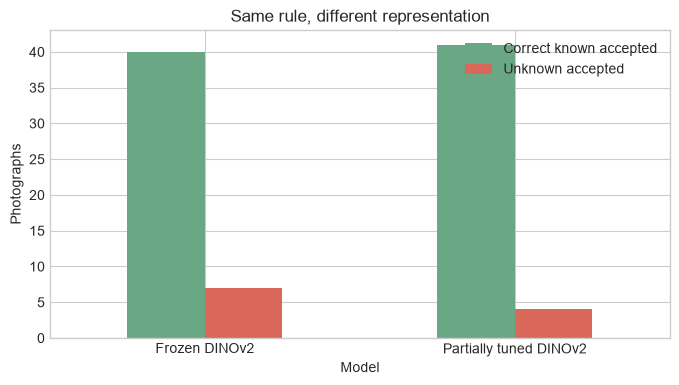

In [7]:
ax = same_rule.set_index("Model")[
    ["Correct known accepted", "Unknown accepted"]
].plot.bar(figsize=(8, 4), color=["#6aa784", "#d9685a"])
ax.set_ylabel("Photographs")
ax.set_title("Same rule, different representation")
plt.xticks(rotation=0)
plt.show()

## 10. What improved

With maximum similarity, fine tuning raises correct known acceptance from 40 to 41 and lowers unknown false acceptance from 7 to 4. This is evidence that the tuned representation separates these validation images better. The two threshold numbers should not be compared directly because fine tuning changes the embedding geometry.

## 11. Tuned embedding alternatives

After freezing the checkpoint, I can inspect the same four confidence signals on its embeddings. This is still validation analysis, not a final test result.

In [8]:
tuned = pd.DataFrame(
    [
        ("Maximum similarity", 41, 4, 0.611551),
        ("Identity margin", 40, 3, 0.105529),
        ("Five neighbor agreement", 42, 14, 0.800000),
        ("Prototype similarity", 40, 0, 0.604001),
    ],
    columns=["Confidence", "Correct known accepted", "Unknown accepted", "Threshold"],
)
tuned

,Confidence,Correct known accepted,Unknown accepted,Threshold
0,Maximum similarity,41,4,0.611551
1,Identity margin,40,3,0.105529
2,Five neighbor agreement,42,14,0.800000
3,Prototype similarity,40,0,0.604001


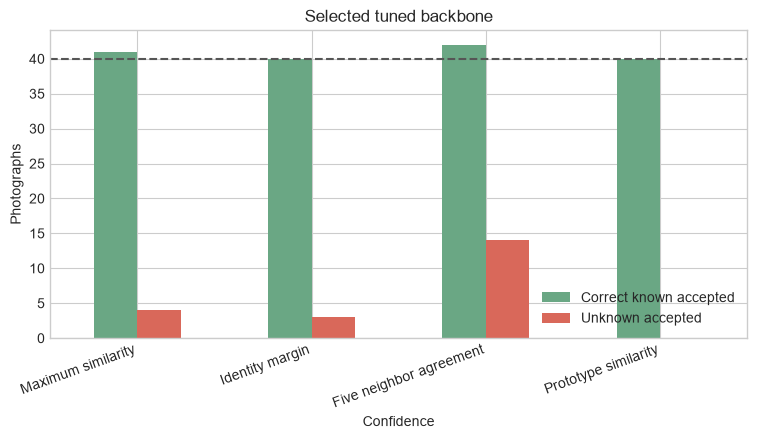

In [9]:
ax = tuned.set_index("Confidence")[
    ["Correct known accepted", "Unknown accepted"]
].plot.bar(figsize=(9, 4), color=["#6aa784", "#d9685a"])
ax.axhline(40, color="#555555", linestyle="--")
ax.set_ylabel("Photographs")
ax.set_title("Selected tuned backbone")
plt.xticks(rotation=20, ha="right")
plt.show()

## 12. The prototype result

Prototype similarity accepts 40 correct known photos and rejects all 51 unknown photos. A prototype averages the 14 Session 1 vectors for one doll, so it emphasizes features that are consistent across its reference views. This may reduce the influence of one unusually similar reference photo.

## 13. Classifier head confidence

The classification head produces seven logits. Softmax turns them into probabilities across those seven known classes. Maximum probability uses the winning probability. Probability margin subtracts the runner up probability from the winner.

In [10]:
classifier = pd.DataFrame(
    [
        ("Maximum probability", 40, 1, 0.993061),
        ("Probability margin", 40, 0, 0.990010),
    ],
    columns=["Confidence", "Correct known accepted", "Unknown accepted", "Threshold"],
)
classifier

,Confidence,Correct known accepted,Unknown accepted,Threshold
0,Maximum probability,40,1,0.993061
1,Probability margin,40,0,0.990010


## 14. Why a probability near one can still be wrong

Softmax distributes all probability among the seven classes it knows. It has no built in unknown class. An unfamiliar image can still receive a very high probability if one known logit is larger than the others. The threshold is an empirical safety rule, not a guarantee.

In [11]:
summary = pd.DataFrame(
    [
        ("Frozen embedding, maximum similarity", 40, 7),
        ("Tuned embedding, maximum similarity", 41, 4),
        ("Tuned embedding, prototype similarity", 40, 0),
        ("Tuned classifier, probability margin", 40, 0),
    ],
    columns=["Candidate", "Correct known accepted", "Unknown accepted"],
)
summary

,Candidate,Correct known accepted,Unknown accepted
0,"Frozen embedding, maximum similarity",40,7
1,"Tuned embedding, maximum similarity",41,4
2,"Tuned embedding, prototype similarity",40,0
3,"Tuned classifier, probability margin",40,0


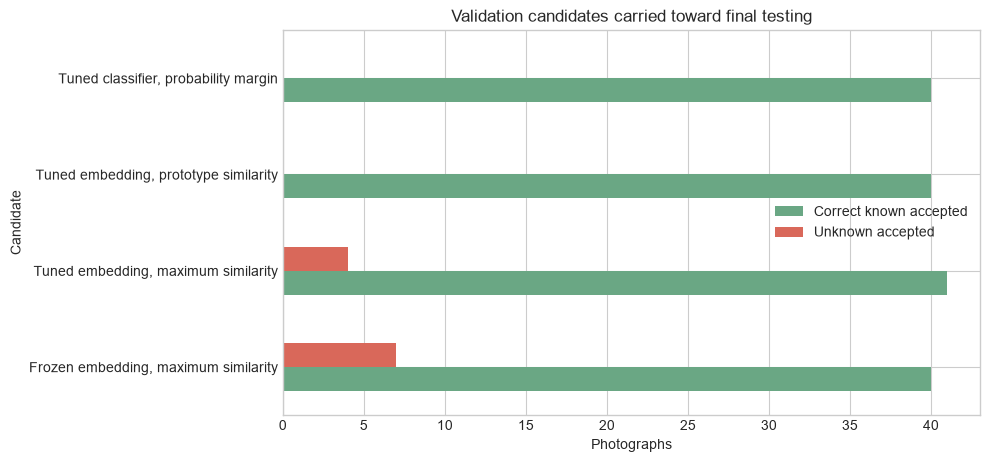

In [12]:
ax = summary.set_index("Candidate")[
    ["Correct known accepted", "Unknown accepted"]
].plot.barh(figsize=(9, 5), color=["#6aa784", "#d9685a"])
ax.set_xlabel("Photographs")
ax.set_title("Validation candidates carried toward final testing")
plt.show()

## 15. What is frozen and what is not

The frozen baseline is maximum similarity with frozen DINOv2. The exact tuned checkpoint is also frozen. Tuned prototype similarity and classifier probability margin are promising candidates, but zero errors on 51 unknown validation photos is not enough evidence to call either solved.

## 16. Why there is no per identity threshold yet

Each known identity has only six Session 2 photos. A separate threshold for every identity would be calibrated from too little data and could overfit individual views. A global threshold is easier to explain and more defensible at this dataset size.

## 17. Final decision and known test result

I decided not to collect third party social media images. Unknown rejection therefore remains a validation result only. Session 3 was opened once for the final known test after every choice was frozen. Frozen nearest and tuned nearest each identified 41 of 42 photos correctly. Tuned prototype and the classifier each identified 40 of 42. All four systems placed the correct identity in the top three for every photo.

The strict rejection thresholds accepted 33 frozen nearest predictions, 35 tuned nearest predictions, 34 tuned prototype predictions, and 38 classifier predictions. Every accepted prediction was correct, but none retained the 95 percent known acceptance target on the new session. This shows that raw identity ranking generalized better than the validation selected confidence thresholds.

In [13]:
print("Frozen checkpoint: c62a6ff28d2e")
print("Frozen baseline confidence: maximum similarity")
print("Session 3 accessed once for final known test: True")
print("Independent unknown final test: not available")
print("Unknown rejection result: validation only")

Frozen checkpoint: c62a6ff28d2e
Frozen baseline confidence: maximum similarity
Session 3 accessed once for final known test: True
Independent unknown final test: not available
Unknown rejection result: validation only
